In [69]:
# import dependencies
import os
import skimage as ski
import matplotlib.pyplot as plt
from skimage.color import rgb2gray
import numpy as np
import pandas as pd
from skimage import filters
from skimage.feature import hog
from skimage import data, exposure
from sklearn.decomposition import PCA

Text(0.5, 1.0, 'BROOKES BIRDWING')

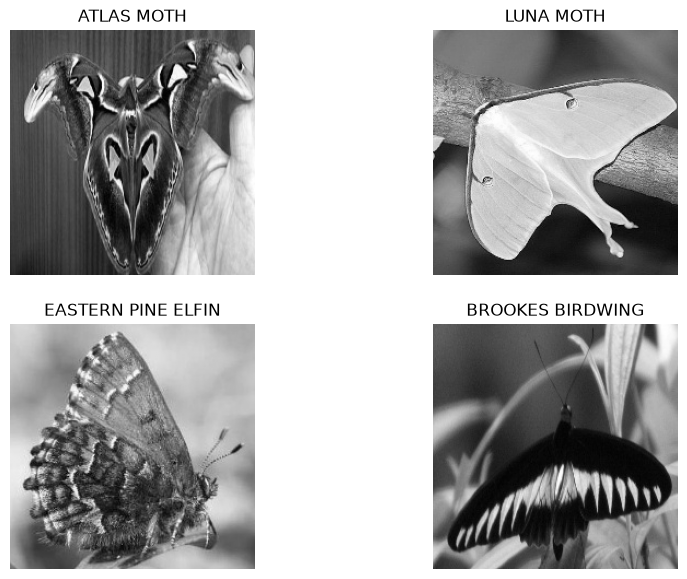

In [70]:
# choose one image from each class
dir = "./data/img/butterfly/train"
cats = ["ATLAS MOTH","LUNA MOTH","EASTERN PINE ELFIN","BROOKES BIRDWING"]
filenames = ["akivid2_mp4-0058_jpg.rf.27907efb6e537bfa34026e7b00c0318d.jpg",
             "akivid4_mp4-0018_jpg.rf.e253cd9588ba553ea55902beccd02a73.jpg",
             "akivid3_mp4-0009_jpg.rf.e1070ece91fb225a3a105fb9ba35a374.jpg",
             "akivid5_mp4-0055_jpg.rf.ee6f84676fa9b8986956b3663f56828f.jpg"]
filenames = ["001.jpg",
             "001.jpg",
             "002.jpg",
             "001.jpg"]
dirs = []
for i in range(4):
    dirs.append(os.path.join(dir, cats[i], filenames[i]))

imgs = []

# load in the images and turn them grey
for filepath in dirs:
    imgs.append(rgb2gray(ski.io.imread(filepath)))

# display images
fig = plt.figure(figsize=(10, 7))
plt.subplot(2, 2, 1)  # 2 rows, 2 columns, first position
plt.imshow(imgs[0], cmap='gray')  
plt.axis('off')  # Hide the axis labels
plt.title(cats[0]) 
plt.subplot(2, 2, 2)
plt.imshow(imgs[1], cmap='gray')  
plt.axis('off') 
plt.title(cats[1]) 
plt.subplot(2, 2, 3)  
plt.imshow(imgs[2], cmap='gray')  
plt.axis('off') 
plt.title(cats[2]) 
plt.subplot(2, 2, 4)  
plt.imshow(imgs[3], cmap='gray')  
plt.axis('off') 
plt.title(cats[3]) 

In [71]:
# get pixel angles
def angle(dx, dy):
    """Calculate the angles between horizontal and vertical operators."""
    return np.mod(np.arctan2(dy, dx), np.pi)

def sobeler(I):
    angle_sobel = angle(filters.sobel_h(I),
                        filters.sobel_v(I))
    return angle_sobel

pixel_angles = []
for i in range(4):
    pixel_angles.append(sobeler(imgs[i]))

In [72]:
# obtain histograms with 36 bins
histograms = []
binsets = []
for i in range(4):
    counts, bins = ski.exposure.histogram(pixel_angles[i],nbins=36)
    histograms.append(counts)
    binsets.append(bins)

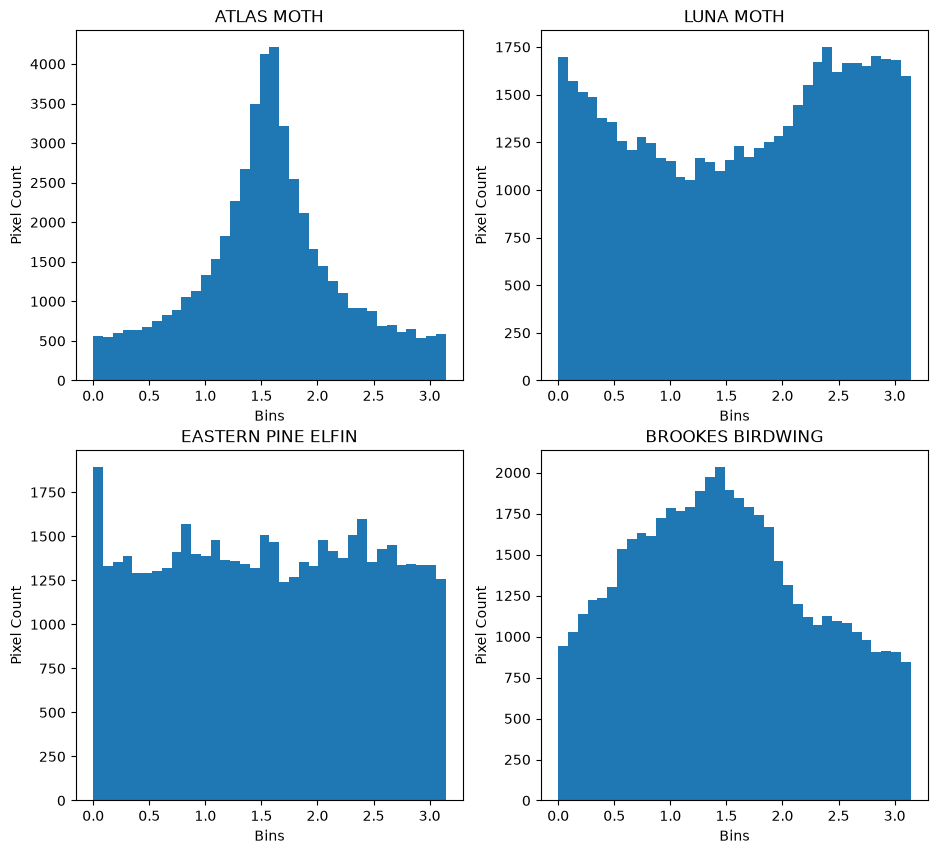

In [73]:
# plot the histograms

fig = plt.figure(figsize=(11, 10))
for i in range(4):
    plt.subplot(2,2,i+1)
    plt.bar(binsets[i],histograms[i],width=np.pi/36)
    plt.title(cats[i])
    plt.xlabel('Bins')
    plt.ylabel('Pixel Count')
plt.show()

In [74]:
# perform histogram comparison through pairwise distance metrics
# specifically comparing the example bubble and example kick images
from sklearn.metrics.pairwise import pairwise_distances

h1=histograms[0].reshape(1,-1)
h2=histograms[1].reshape(1,-1)

#manually checked the euclidean distance between them to ensure my implementation was correct
#import math
#eu_dis = 0
#for i in range(36):
#    eu_dis += (histograms[0][i]-histograms[1][i]) ** 2
#eu_dis = math.sqrt(eu_dis)
#print(eu_dis)

# Euclidean distance = 6981.097764678561
eu_distance = pairwise_distances(h1, Y=h2, metric='euclidean')[0][0]
print("Euclidean Distance:")
print(eu_distance)
# Manhattan distance = 27364.0
print("Manhattan Distance:")
ma_distance = pairwise_distances(h1, Y=h2, metric='manhattan')[0][0]
print(ma_distance)
# Cosine distance = 0.012264435193797052
print("Cosine Distance:")
co_distance = pairwise_distances(h1, Y=h2, metric='cosine')[0][0]
print(co_distance)

Euclidean Distance:
7057.357154062702
Manhattan Distance:
34216.0
Cosine Distance:
0.2632151373315704


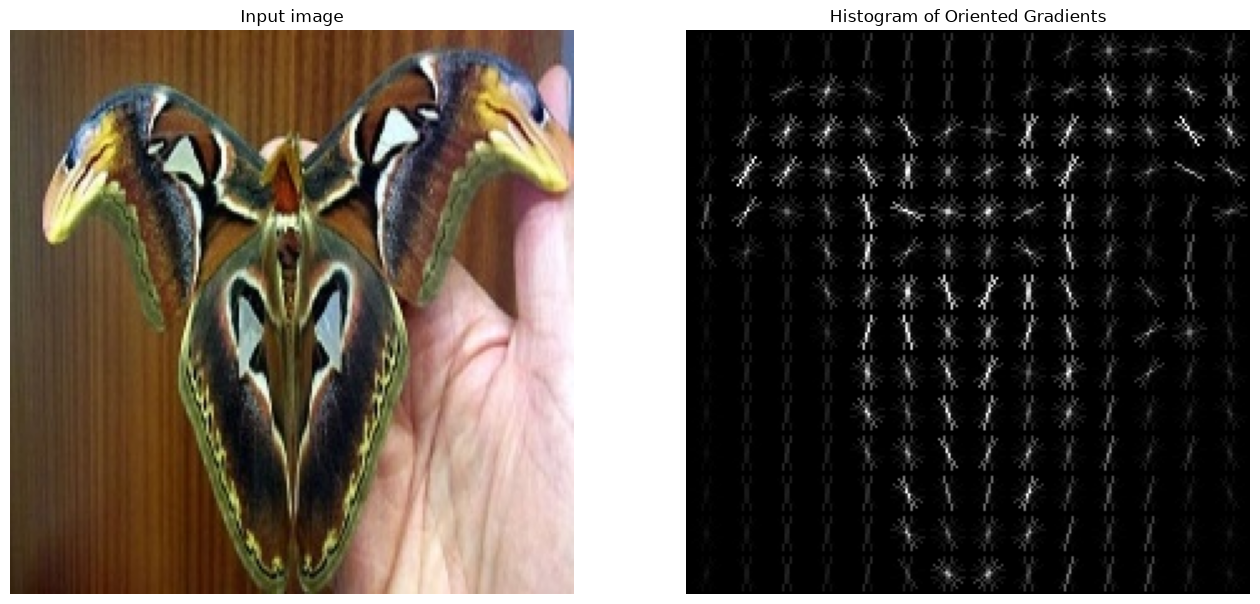

In [75]:
# Compute and display HOG of image
# in this implementation, i kept the default values used in the example
# although the quality of the edge detection can be significantly improved by reducing the pixels
# per cell
image = imgs[0]
image = ski.io.imread(dirs[0])

fd, hog_image = hog(
    image,
    orientations=8,
    pixels_per_cell=(16, 16),
    cells_per_block=(1, 1),
    visualize=True,
    channel_axis=-1,
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8), sharex=True, sharey=True)

ax1.axis('off')
ax1.imshow(image, cmap=plt.cm.gray)
ax1.set_title('Input image')

# Rescale histogram for better display
hog_image_rescaled = exposure.rescale_intensity(hog_image, in_range=(0, 40))

ax2.axis('off')
ax2.imshow(hog_image_rescaled, cmap=plt.cm.gray)
ax2.set_title('Histogram of Oriented Gradients')
plt.show()

In [76]:
# get every image & convert into edge histograms
cats = ["ATLAS MOTH","LUNA MOTH","EASTERN PINE ELFIN","BROOKES BIRDWING"]
hists = []
binsets = []
targets = []
import os
for i in range(4):
    for x in os.listdir(os.path.join(dir, cats[i])):
        if x.endswith(".jpg"):
            img = ski.io.imread(os.path.join(dir,cats[i],x))
            gray = rgb2gray(img)
            pixel_angles = sobeler(gray)
            counts, bins = ski.exposure.histogram(pixel_angles,nbins=36)
            hists.append(counts)
            binsets.append(bins)
            targets.append(i)
print(np.array(hists).shape)

(547, 36)


In [77]:
# take the edge histograms & perform PCA
hists_df = pd.DataFrame(data=np.array(hists), columns=binsets[0])

hists_pca = PCA(n_components=2).fit_transform(hists_df)

#pca_df = pd.DataFrame(hists_pca,columns=['PC1','PC2'])
#pca_df.head()
#sns.heatmap(hists_df.corr())

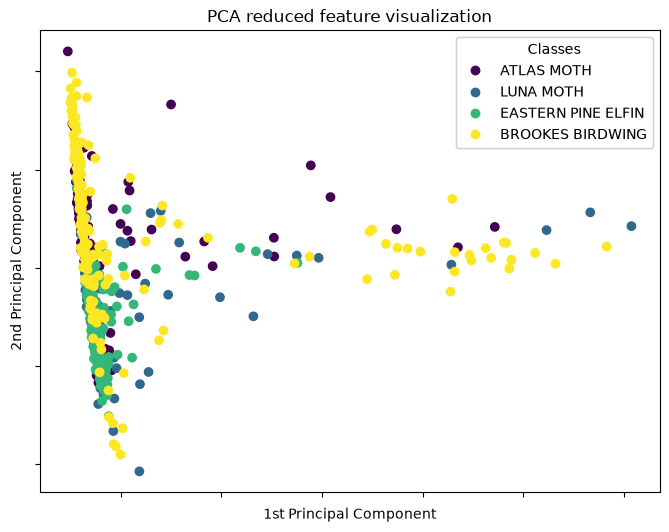

In [78]:
# display results
fig = plt.figure(1, figsize=(8, 6))
ax = fig.add_subplot(111)
scatter = ax.scatter(
    hists_pca[:, 0],
    hists_pca[:, 1],
    c=targets
)

ax.set(
    title="PCA reduced feature visualization",
    xlabel="1st Principal Component",
    ylabel="2nd Principal Component"
)

ax.xaxis.set_ticklabels([])
ax.yaxis.set_ticklabels([])

legend = ax.legend(
    scatter.legend_elements()[0],
    cats,
    loc="upper right",
    title="Classes",
)

ax.add_artist(legend)

plt.show()

In [79]:
# There are no visually separable classes

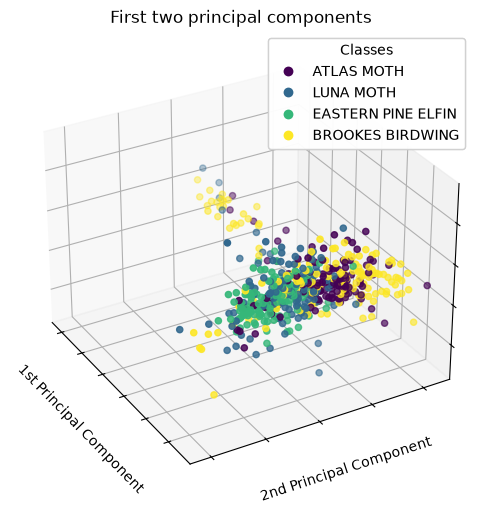

In [80]:
# experiments
subcats = ["bubble","kick","lash","rush"]
subcats = ["ATLAS MOTH","LUNA MOTH","EASTERN PINE ELFIN","BROOKES BIRDWING"]
# subcats = cats
hists = []
binsets = []
targets = []
superhists = []
count = 0
class_counts = [0,0,0,0,0]
for i in range(len(subcats)):
    superhists.append([])
    for x in os.listdir(os.path.join(dir, subcats[i])):
        if x.endswith(".jpg"):
            img = ski.io.imread(os.path.join(dir,subcats[i],x))
            gray = rgb2gray(img)
            pixel_angles = sobeler(gray)
            counts, bins = ski.exposure.histogram(pixel_angles,nbins=36)
            hists.append(counts)
            binsets.append(bins)
            if len(superhists[i]) == 0:
                superhists[i] = counts.copy()
                class_counts[i] = 1
            else:
                class_counts[i] += 1
                for j in range(36):
                    superhists[i][j] += counts[j]
            targets.append(i)
# take the edge histograms & perform PCA
avg_hist = superhists.copy()
for i in range(len(subcats)):
    for j in range(36):
        avg_hist[i][j] = superhists[i][j]/class_counts[i]
hists_df = pd.DataFrame(data=np.array(hists))

hists_pca = PCA(n_components=3).fit_transform(hists_df)

# display results
fig = plt.figure(1, figsize=(8, 6))
ax = fig.add_subplot(111,projection="3d", elev=-150, azim=30)
scatter = ax.scatter(
    hists_pca[:, 0],
    hists_pca[:, 1],
    hists_pca[:, 2],
    c=targets
)

ax.set(
    title="First two principal components",
    xlabel="1st Principal Component",
    ylabel="2nd Principal Component"
)

ax.xaxis.set_ticklabels([])
ax.yaxis.set_ticklabels([])
ax.zaxis.set_ticklabels([])

legend = ax.legend(
    scatter.legend_elements()[0],
    subcats,
    loc="upper right",
    title="Classes",
)

ax.add_artist(legend)

plt.show()

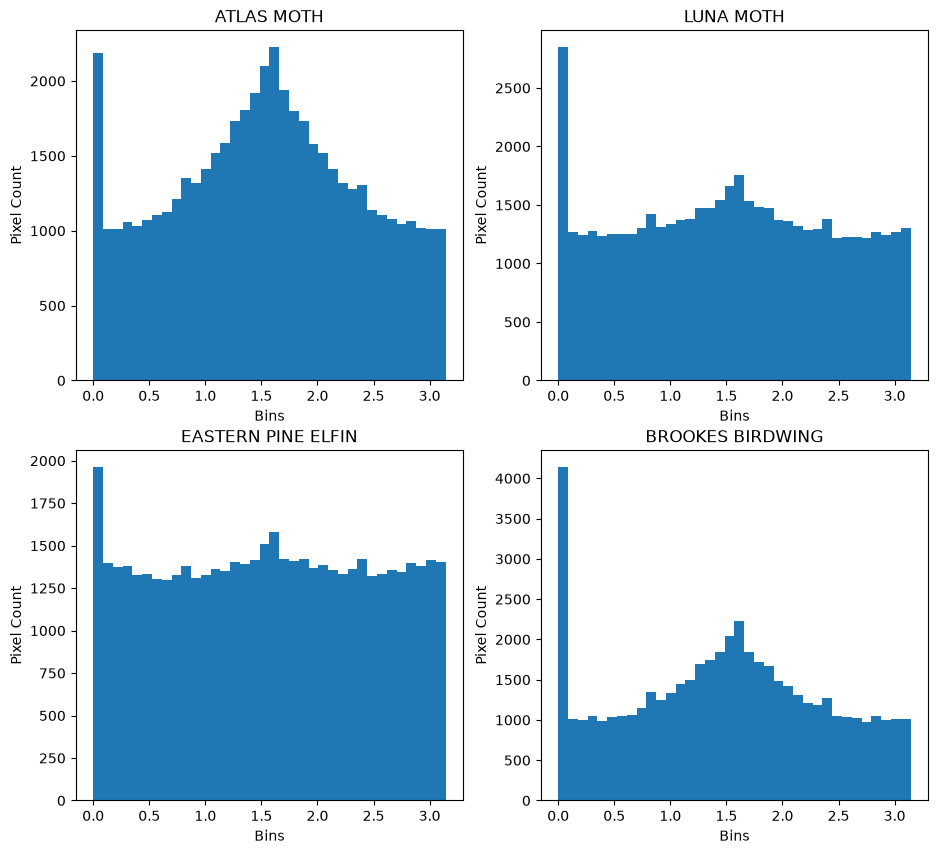

In [81]:
# plot the histograms

fig = plt.figure(figsize=(11, 10))
for i in range(4):
    plt.subplot(2,2,i+1)
    plt.bar(binsets[i],avg_hist[i],width=np.pi/36)
    plt.title(cats[i])
    plt.xlabel('Bins')
    plt.ylabel('Pixel Count')
plt.show()

In [82]:
print("Class Counts: ")
for i in range(4):
    print("\t"+subcats[i]+" "+str(class_counts[i]))

Class Counts: 
	ATLAS MOTH 129
	LUNA MOTH 117
	EASTERN PINE ELFIN 136
	BROOKES BIRDWING 165
